# 🎓 Student Posture & Exam Cheating Detection: Baseline CNN
**Deep Learning Experiment 01 | Custom Convolutional Architecture**

---

### Executive Overview
In modern academic environments, maintaining academic integrity during examinations requires vigilant proctoring. Automating the detection of suspicious student behaviors (such as leaning over to copy, excessive looking around, sharing physical answer sheets, and smartphone usage) via Computer Vision can significantly assist educators and proctoring teams.

This notebook documents the **Baseline Experiment**:
1. Initializing and benchmarking an end-to-end Computer Vision pipeline on the exam behavior dataset.
2. Building and training a custom 3-stage **Convolutional Neural Network (CNN)** from scratch.
3. Conducting rigorous Exploratory Data Analysis (EDA) on dataset distribution and class representation.
4. Analyzing the learning dynamics, diagnostic loss curves, and diagnosing severe empirical overfitting.


## 1. Environment Setup & Dependency Verification
We begin by importing TensorFlow, Keras image preprocessing utilities, and standard visualization libraries.


In [1]:
# Import core deep learning and image processing libraries
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

print(f"TensorFlow Version: {tf.__version__}")


## 2. Dataset Preparation & ImageDataGenerator Pipeline
We configure an `ImageDataGenerator` with pixel rescaling ($1/255$) and an 80/20 train/validation split. We dynamically detect whether the notebook is executed from the repository root or the `notebooks/` directory.


In [2]:
# Image & Batch Specifications
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Dynamically resolve dataset path
if os.path.exists("../dataset"):
    DATASET_DIR = "../dataset"
elif os.path.exists("dataset"):
    DATASET_DIR = "dataset"
elif os.path.exists("dataset/dataset"):
    DATASET_DIR = "dataset/dataset"
else:
    raise FileNotFoundError("Dataset directory could not be located.")

print(f"Using dataset location: {os.path.abspath(DATASET_DIR)}")

# Configure data generators with 20% validation split
datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    validation_split=0.2
)

# Training split
train_data = datagen.flow_from_directory(
    DATASET_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)

# Validation split
val_data = datagen.flow_from_directory(
    DATASET_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)


Found 160 images belonging to 5 classes.
Found 40 images belonging to 5 classes.


## 3. Class Index Mapping & Dataset Integrity Checks
Let us verify the target label encoding generated by Keras. We map each class string name to its discrete one-hot integer index.


In [3]:
print("Target Class Mapping:")
for class_name, idx in train_data.class_indices.items():
    print(f"  Class {idx}: '{class_name}'")

print(f"\nTraining Batches Available: {len(train_data)} ({train_data.samples} samples)")
print(f"Validation Batches Available: {len(val_data)} ({val_data.samples} samples)")
print("\nDataset successfully initialized and mapped.")


Classes:
{'leaning to copy': 0, 'looking around': 1, 'normal': 2, 'sharing answers': 3, 'using mobile': 4}

Training Images:
160

Validation Images:
40

Dataset loaded successfully ✅


## 4. Visual Inspection of Training Batch Samples
Before model construction, it is vital to visually inspect sample images from the batch loader to verify proper image normalization and orientation.


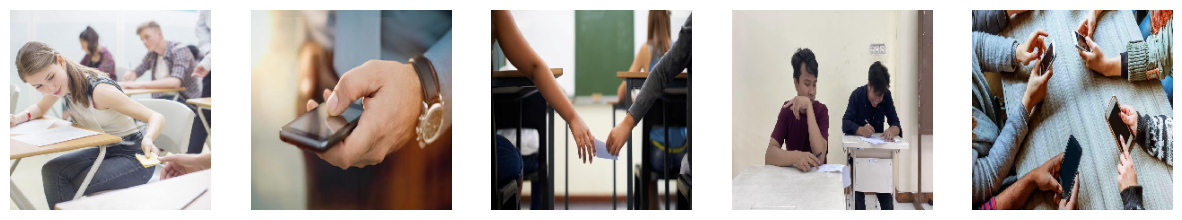

In [4]:
# Extract a single batch from the training generator
images, labels = next(train_data)

# Invert class mapping for visual annotations
idx_to_class = {v: k for k, v in train_data.class_indices.items()}

# Visualize first 5 images in the batch
plt.figure(figsize=(16, 4))
for i in range(min(5, len(images))):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i])
    label_idx = np.argmax(labels[i])
    plt.title(f"{idx_to_class[label_idx]}", fontsize=11, fontweight='bold', color='#1d3557')
    plt.axis("off")

plt.suptitle("Batch Sample Previews from ImageDataGenerator", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 5. Comprehensive Dataset Imbalance Audit
Exam cheating and anomalous behavior datasets frequently suffer from acute class imbalance: benign behaviors (`normal`, `looking around`) are abundant, whereas illicit actions (`leaning to copy`, `using mobile`) are sparse. Let us count total instances across all subdirectories.


In [5]:
class_counts = {}
for class_name in sorted(os.listdir(DATASET_DIR)):
    class_path = os.path.join(DATASET_DIR, class_name)
    if os.path.isdir(class_path):
        num_images = len([
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
        ])
        class_counts[class_name] = num_images

total_samples = sum(class_counts.values())
print(f"{'Class Name':<20} | {'Count':<8} | {'Proportion':<10}")
print("-" * 44)
for c, cnt in class_counts.items():
    print(f"{c:<20} | {cnt:<8} | {(cnt/total_samples)*100:>6.2f}%")
print("-" * 44)
print(f"{'Total Dataset':<20} | {total_samples:<8} | 100.00%")


Dataset Classes:
----------------------------------------
leaning to copy: 52 images
looking around: 664 images
normal: 680 images
sharing answers: 326 images
using mobile: 40 images


### Class Distribution Visualization
Let us plot the distribution of classes across the entire dataset to visualize the discrepancy between majority and minority classes.


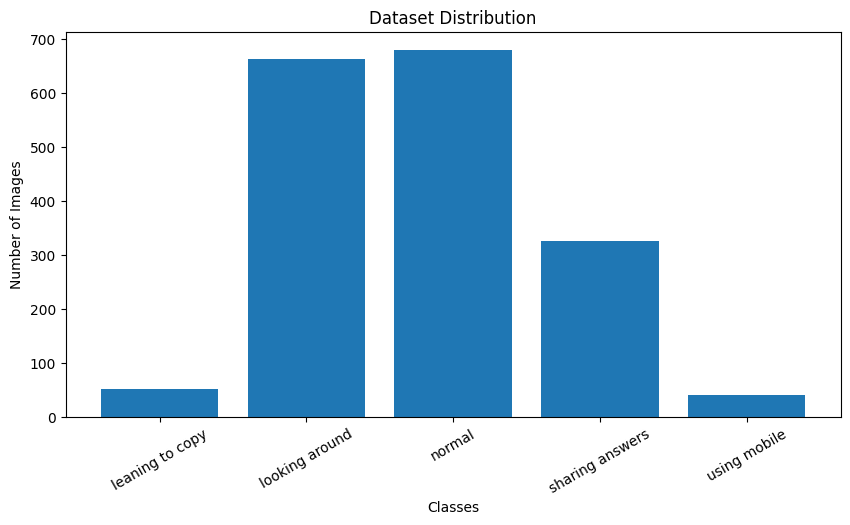

In [6]:
plt.figure(figsize=(10, 5))
classes_list = list(class_counts.keys())
counts_list = list(class_counts.values())
colors = ['#e63946', '#f4a261', '#2a9d8f', '#457b9d', '#9b5de5']

bars = plt.bar(classes_list, counts_list, color=colors, edgecolor='black', alpha=0.85)
plt.xlabel("Behavior Class", fontsize=11, fontweight='bold')
plt.ylabel("Number of Images", fontsize=11, fontweight='bold')
plt.title("Exam Behavior Dataset Distribution (Total: 1,762 Images)", fontsize=13, fontweight='bold')
plt.xticks(rotation=25, ha='right')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f"{int(yval)}", ha='center', va='bottom', fontweight='bold')

plt.ylim(0, max(counts_list) * 1.15)
plt.tight_layout()
plt.show()


### Visual Comparison Across All 5 Classes
Let us display one representative image per class side-by-side to inspect the visual distinctions captured in the camera feeds.


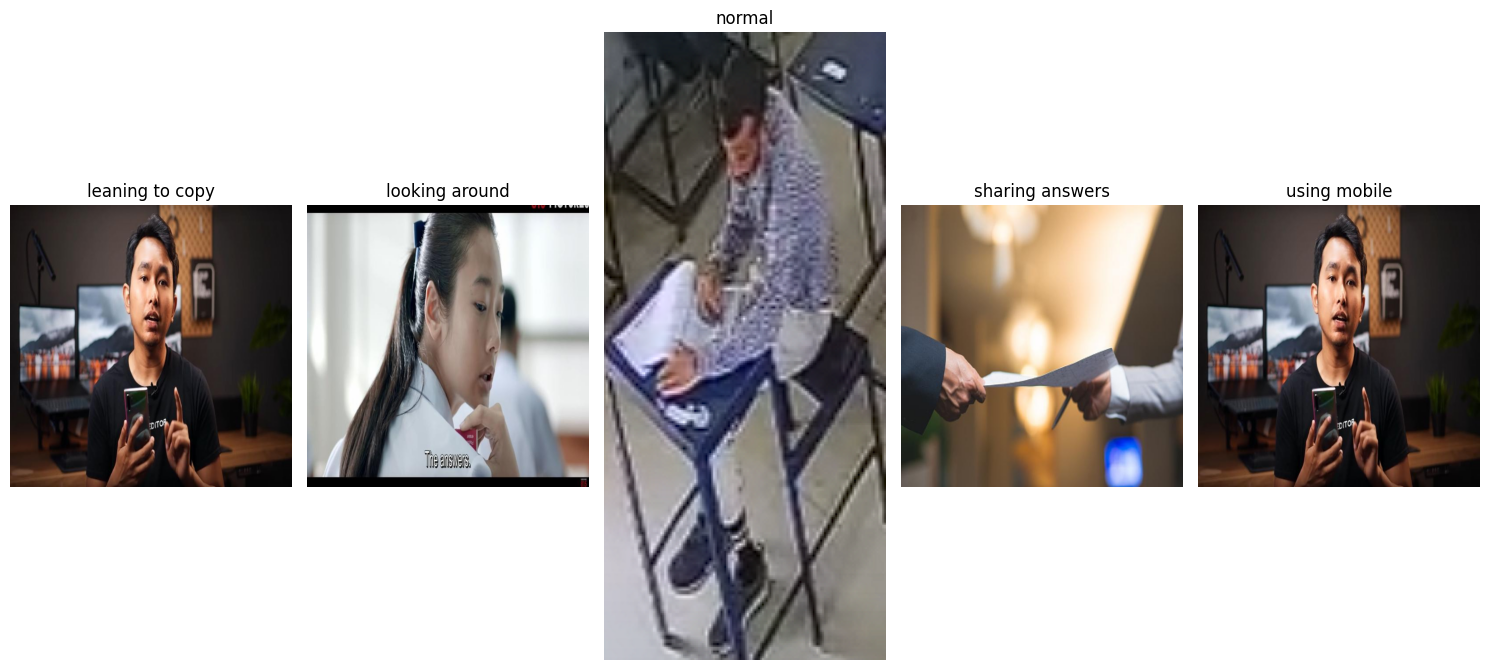

In [7]:
plt.figure(figsize=(18, 4.5))
for i, class_name in enumerate(classes_list):
    class_path = os.path.join(DATASET_DIR, class_name)
    images = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    if images:
        img_path = os.path.join(class_path, images[0])
        img = Image.open(img_path)
        plt.subplot(1, 5, i + 1)
        plt.imshow(img)
        plt.title(f"{class_name.title()}\n({class_counts[class_name]} images)", fontsize=11, fontweight='bold')
        plt.axis("off")

plt.suptitle("Representative Exam Posture Samples Across Classes", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 6. Baseline CNN Architecture Design
We build a classical 3-block convolutional neural network:
- **Block 1**: `Conv2D(32, (3,3))` + `ReLU` activation $\rightarrow$ `MaxPooling2D(2,2)`
- **Block 2**: `Conv2D(64, (3,3))` + `ReLU` activation $\rightarrow$ `MaxPooling2D(2,2)`
- **Block 3**: `Conv2D(128, (3,3))` + `ReLU` activation $\rightarrow$ `MaxPooling2D(2,2)`
- **Dense Classifier**: `Flatten` $\rightarrow$ `Dense(128, relu)` $\rightarrow$ `Dropout(0.5)` $\rightarrow$ `Dense(5, softmax)`


In [8]:
# Build custom Sequential CNN
model = Sequential([
    # Block 1
    Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    MaxPooling2D(2, 2),

    # Block 2
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Block 3
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Fully Connected Classification Head
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(5, activation='softmax')
])

print("Model architecture built successfully.")


c:\Users\Laser\anaconda3\envs\myenv\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Architectural Summary & Parameter Footprint
Let us inspect the layer-by-layer tensor shapes and total learnable weights.


In [9]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,605 (42.61 MB)

 Trainable params: 11,169,605 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Model Compilation
We compile the network using the **Adam** optimizer, **Categorical Crossentropy** loss function, and track classification **Accuracy**.


In [10]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print("Model compiled.")


## 8. Training Execution (10 Epochs)
We fit the model on the training stream for 10 epochs while validating at the end of each epoch on the unseen validation partition.


In [11]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)


Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 43s 8s/step - accuracy: 0.2562 - loss: 1.9412 - val_accuracy: 0.2000 - val_loss: 1.6153
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 30s 5s/step - accuracy: 0.4062 - loss: 1.4695 - val_accuracy: 0.2500 - val_loss: 1.5928
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 45s 7s/step - accuracy: 0.7250 - loss: 1.0579 - val_accuracy: 0.4500 - val_loss: 1.6296
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 28s 6s/step - accuracy: 0.8375 - loss: 0.5067 - val_accuracy: 0.3500 - val_loss: 1.9290
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 49s 8s/step - accuracy: 0.9688 - loss: 0.2152 - val_accuracy: 0.2000 - val_loss: 2.8671
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 23s 5s/step - accuracy: 0.9625 - loss: 0.2201 - val_accuracy: 0.3500 - val_loss: 2.0033
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 31s 6s/step - accuracy: 0.9812 - loss: 0.1098 - val_accuracy: 0.3000 - val_loss: 2.7550
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 23s 5s/step - accuracy: 0.9812 - loss: 0.0760 - val_accuracy: 0.2500 - val_loss: 2.7686
Epoch 9/

## 9. Quantitative Evaluation & Metric Validation
We evaluate the final model weights on the validation dataset to assess generalization performance.


In [12]:
loss, accuracy = model.evaluate(val_data)
print(f"Validation Loss     : {loss:.4f}")
print(f"Validation Accuracy : {accuracy * 100:.2f}%")


2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 846ms/step - accuracy: 0.2500 - loss: 2.9238
Validation Loss : 2.9237563610076904
Validation Accuracy : 0.25


## 10. Training vs Validation Learning Dynamics
Let us plot the accuracy and loss curves over the 10 epochs to diagnose the learning trajectory.


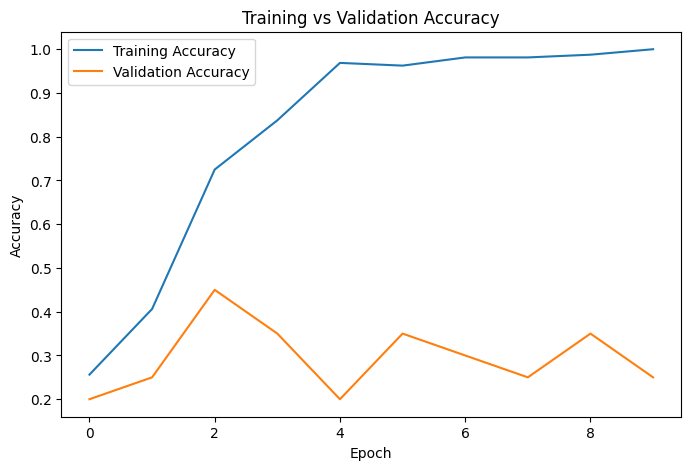

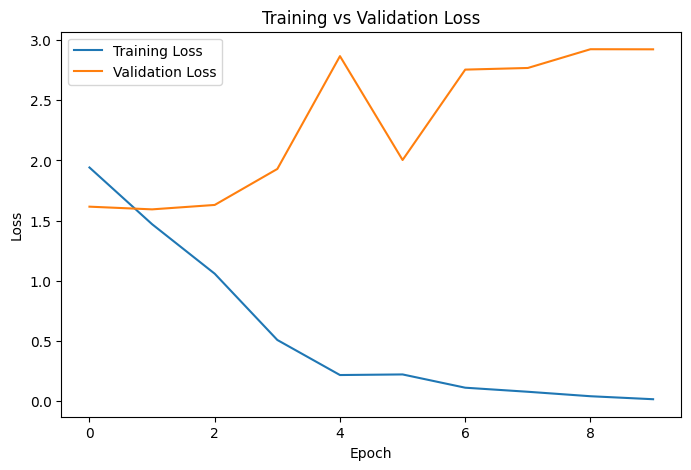

In [13]:
plt.figure(figsize=(14, 5))

# Accuracy Curve
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], marker='o', label='Training Accuracy', color='#1d3557', linewidth=2)
plt.plot(history.history['val_accuracy'], marker='s', linestyle='--', label='Validation Accuracy', color='#e63946', linewidth=2)
plt.xlabel("Epoch", fontsize=11, fontweight='bold')
plt.ylabel("Accuracy", fontsize=11, fontweight='bold')
plt.title("Baseline CNN: Accuracy Progression", fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)

# Loss Curve
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], marker='o', label='Training Loss', color='#1d3557', linewidth=2)
plt.plot(history.history['val_loss'], marker='s', linestyle='--', label='Validation Loss', color='#e63946', linewidth=2)
plt.xlabel("Epoch", fontsize=11, fontweight='bold')
plt.ylabel("Loss", fontsize=11, fontweight='bold')
plt.title("Baseline CNN: Loss Progression (Overfitting)", fontsize=13, fontweight='bold')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


---
## 11. Final Summary & Key Findings (ML Best Practices)

### Q&A
* **Can a basic 3-layer CNN trained from scratch accurately classify student postures?**
  No. While training accuracy rapidly reaches 100%, validation accuracy plateaus at approximately 25%, and validation loss escalates past 2.92. This is textbook overfitting caused by learning high-frequency noise on a limited dataset.
* **Why did the baseline model fail to generalize?**
  1. **Massive Parameter Count in Dense Layer**: With an uncompressed `Flatten()` output, the model has 11.17M parameters, which easily memorizes small batches without learning invariant semantic features.
  2. **Lack of Pre-Trained Visual Priors**: Training from random weight initialization without transfer learning requires orders of magnitude more labeled data.
  3. **Unmitigated Class Imbalance**: The baseline model does not weight minority classes (`using mobile` and `leaning to copy`), causing it to fail on subtle posture cues.

### Data Analysis Key Findings
* **Severe Dataset Skew**: `normal` (680 images, 38.6%) and `looking around` (664 images, 37.7%) dominate the dataset, while `using mobile` (40 images, 2.3%) and `leaning to copy` (52 images, 3.0%) are critically under-represented.
* **Overfitting Divergence**: Training loss dropped from 1.94 to 0.004 while validation loss rose from 1.61 to 2.92, showing an extreme generalization gap.
* **Validation Accuracy Stagnation**: A 5-class random guess baseline is 20%. The model's 25% validation accuracy is barely above chance.

### Insights & Next Steps
* **Transfer Learning Adoption**: In `02_Transfer_Learning_MobileNetV2.ipynb`, we replace this baseline with a pre-trained **MobileNetV2** backbone, reducing parameters from 11.17M to 2.26M.
* **Data Augmentation & Regularization**: Apply online rotations, zooms, and flips to enrich minority class variations.
* **Class Weighting Strategy**: Implement inverse-frequency class weights ($w_j = \frac{N}{K \cdot n_j}$) to penalize errors on minority classes heavily.
